In [9]:
# 제가 업로드 드린 페트병/캔 사진으로 KNN 모델 만들어서 학습
# test_img 2개가 각각 페트병인지 캔인지 예측하는 테스트 진행

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Colab_AI 영상처리

from sklearn.neighbors import KNeighborsClassifier

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Colab_AI 영상처리


In [11]:
# * 필요한 데이터 준비 (X :: 문제, Y :: 정답)
#    "제시한 사진이 페트병인지 캔인지를 예측"

# X : 페트병과 캔의 이미지 정보
names = [
    'plastic1.jpg',
    'plastic2.jpg',
    'plastic3.jpg',
    'plastic4.jpg',
    'can1.jpg',
    'can2.jpg',
    'can3.jpg',
    'can4.jpg',
]
X = []    # (1차원 배열을 여러 개 담은) 2차원 배열 구성
for n in names:
  img = cv2.imread('picture/recycle/'+n)

  img = cv2.resize(img, (32, 32))   # 사진을 구성하는 numpy 배열 크기 줄임 (사이즈 통일)
  data = img.reshape(-1)    # 1차원 배열 변환
  X.append(data)
X = np.array(X)

# Y : 군집 데이터 (0은 페트병, 1은 캔)
Y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

In [12]:
# KNN 모델 생성 + 학습
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X, Y)

KNeighborsClassifier(n_neighbors=3)

In [13]:
# 테스트용 사진 불러오기 + 처리
test_name = ['test_img1.png', 'test_img2.png']

# 문제
test = []
for n in test_name:
  img = cv2.imread('picture/recycle/' + n)

  img = cv2.resize(img, (32, 32))
  data = img.reshape(-1)
  test.append(data)
test = np.array(test)

# 정답
answer = np.array([0, 1])

예측값: 1
실제값: 0
캔입니다.


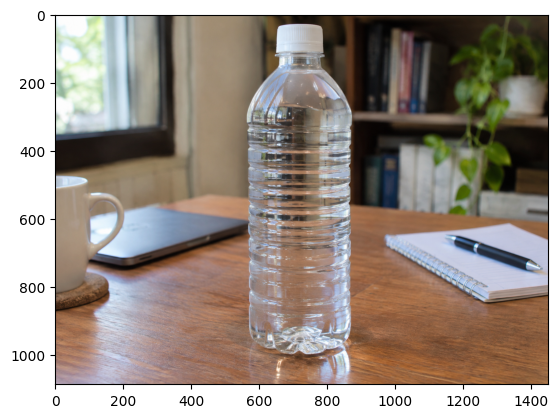

예측값: 1
실제값: 1
캔입니다.


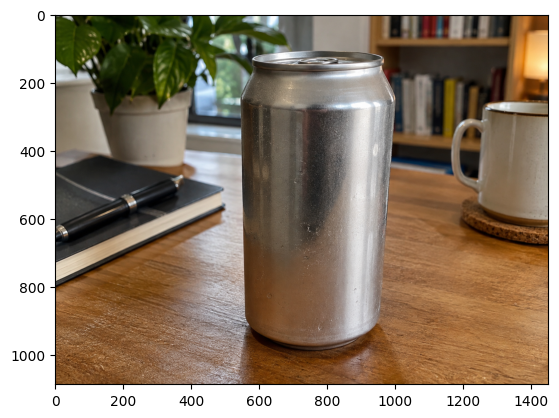

In [17]:
# 예측 진행
result = model.predict(test)

for i in range(2):
  print('예측값:', result[i])
  print('실제값:', answer[i])

  img = cv2.imread('picture/recycle/' + test_name[i])
  img_rgb = cv2.cvtColor(
      img,
      cv2.COLOR_BGR2RGB
  )

  if result[i] == 0:
    print('페트병입니다.')
  else:
    print('캔입니다.')

  plt.imshow(img_rgb)
  plt.show()